In [1]:
import solarpy
import pvlib
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import numpy as np

# Measurement data

In [8]:
start_date = '2026-11-03'
end_date = '2026-11-07'

dmi_data, dmi_meta = solarpy.iotools.get_dmi_metobs(station = '06056',
                                          start=start_date,
                                          end=end_date,
                                          parameters = ['ghi'])

#### Find extra-terrestrial radiation and solar position

In [9]:
solarposition = pvlib.solarposition.get_solarposition(
    time=dmi_data.index, latitude=dmi_meta['latitude'], longitude=dmi_meta['longitude'],
)

dmi_data['solar_zenith'] = solarposition['apparent_zenith']
dmi_data['solar_azimuth'] = solarposition['azimuth']

dni_extra = pvlib.irradiance.get_extra_radiation(dmi_data.index)
cos_sza = np.cos(np.deg2rad(solarposition["apparent_zenith"])).clip(lower=0)
dmi_data['ghi_extra'] = dni_extra * cos_sza

print(dmi_data.head())


parameterId                ghi  solar_zenith  solar_azimuth  ghi_extra
timestamp                                                             
2026-11-03 00:00:00+00:00  0.0    137.477751      18.432519        0.0
2026-11-03 00:10:00+00:00  0.0    137.002478      21.920041        0.0
2026-11-03 00:20:00+00:00  0.0    136.449688      25.349511        0.0
2026-11-03 00:30:00+00:00  0.0    135.822715      28.715053        0.0
2026-11-03 00:40:00+00:00  0.0    135.125149      32.012066        0.0


#### Check BSRN limits

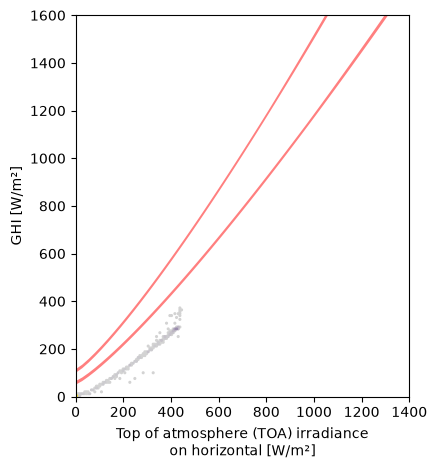

In [ ]:
fig, axes = solarpy.plotting.plot_bsrn_limits(
    irradiance=dmi_data['ghi'],
    component="ghi",
    ghi_extra= dmi_data['ghi_extra'],
)
fig.tight_layout()
# fig.savefig(f"results/measurement_data/ghi_bsrn_limits_{start_date}_{end_date}.png", dpi=300)

#### Checking shading

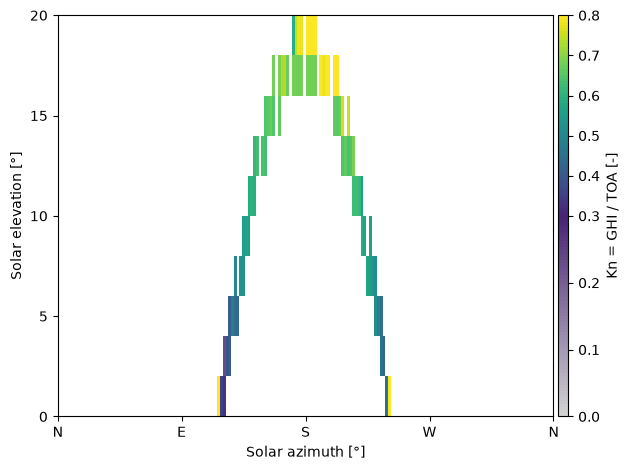

In [ ]:
fig, ax = solarpy.plotting.plot_shading_heatmap(
    value=dmi_data["ghi"] / dmi_data["ghi_extra"],
    solar_azimuth=dmi_data["solar_azimuth"],
    solar_elevation=90-dmi_data["solar_zenith"],
    azimuth_bin_size = 2,
    elevation_bin_size = 2,
    cmap=solarpy.plotting.two_part_colormap(),
    norm=TwoSlopeNorm(vmin=0, vcenter=0.3, vmax=0.8),
    colorbar_label="Kn = GHI / TOA [-]",
)
fig.tight_layout()
# fig.savefig(f"results/measurement_data/ghi_shading_heatmap_{start_date}_{end_date}.png", dpi=300)

#### Checking intraday heatmap

C:\Users\karla\AppData\Local\Temp\ipykernel_39924\1625325284.py:17: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  pd.date_range(dmi_data.index.min(), dmi_data.index.max(), freq="1d"),


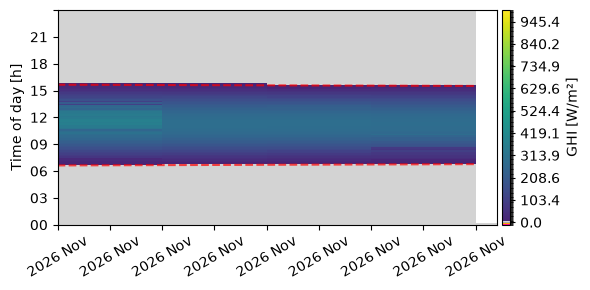

In [ ]:

# Load custom colormap and norm
cmap, norm = solarpy.plotting.irradiance_colormap_and_norm(vmax=1000)

fig, ax = plt.subplots(figsize=(6, 3))

_ = solarpy.plotting.plot_intraday_heatmap(
    time=dmi_data.index,
    values=dmi_data["ghi"],
    cmap=cmap,
    norm=norm,
    colorbar_label="GHI [W/m²]",
    ax=ax,  # pass in existing axes
)

# Overlay sunrise and sunset times
sun_rise_set = pvlib.solarposition.sun_rise_set_transit_spa(
    pd.date_range(dmi_data.index.min(), dmi_data.index.max(), freq="1d"),
    dmi_meta["latitude"],
    dmi_meta["longitude"],
)

sunrise = (
    sun_rise_set["sunrise"] - sun_rise_set["sunrise"].index.normalize()
).dt.total_seconds() / 3600

sunset = (
    sun_rise_set["sunset"] - sun_rise_set["sunset"].index.normalize()
).dt.total_seconds() / 3600


ax.plot(sunrise, c="r", linestyle="dashed", lw=1.5, alpha=0.7)
ax.plot(sunset, c="r", linestyle="dashed", lw=1.5, alpha=0.7)

fig.tight_layout()
# fig.savefig(f"results/measurement_data/ghi_intraday_heatmap_{start_date}_{end_date}.png", dpi=300)

#### Resampling in hourly resolution

In [40]:
dmi_data = dmi_data.resample("1h", closed="right", label="right").mean()
print(dmi_data.head())

parameterId                ghi  solar_zenith  solar_azimuth  ghi_extra
timestamp                                                             
2025-11-02 00:00:00+00:00  0.0    135.812141      26.849423        0.0
2025-11-02 01:00:00+00:00  0.0    130.929844      45.695284        0.0
2025-11-02 02:00:00+00:00  0.0    124.263310      62.010276        0.0
2025-11-02 03:00:00+00:00  0.0    116.546012      76.292918        0.0
2025-11-02 04:00:00+00:00  0.0    108.351327      89.270509        0.0


# Forecast data

In [20]:
forecast_data = pd.read_csv('data/06056_20261103T1500.csv', index_col=0, parse_dates=True)
forecast_data.head()

,dmi_harmonie_arome_europe,metno_nordic,ecmwf_ifs025,ecmwf_aifs025_single,gfs_global,ecmwf_ifs,dmi_seamless,gfs_seamless
date,,,,,,,,
2026-11-03 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-03 01:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-03 02:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-03 03:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-03 04:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Plotting the forecast data

NB: Husk!!! At det measured data skal overlappe med forecast dataet for at nedenstående kan laves

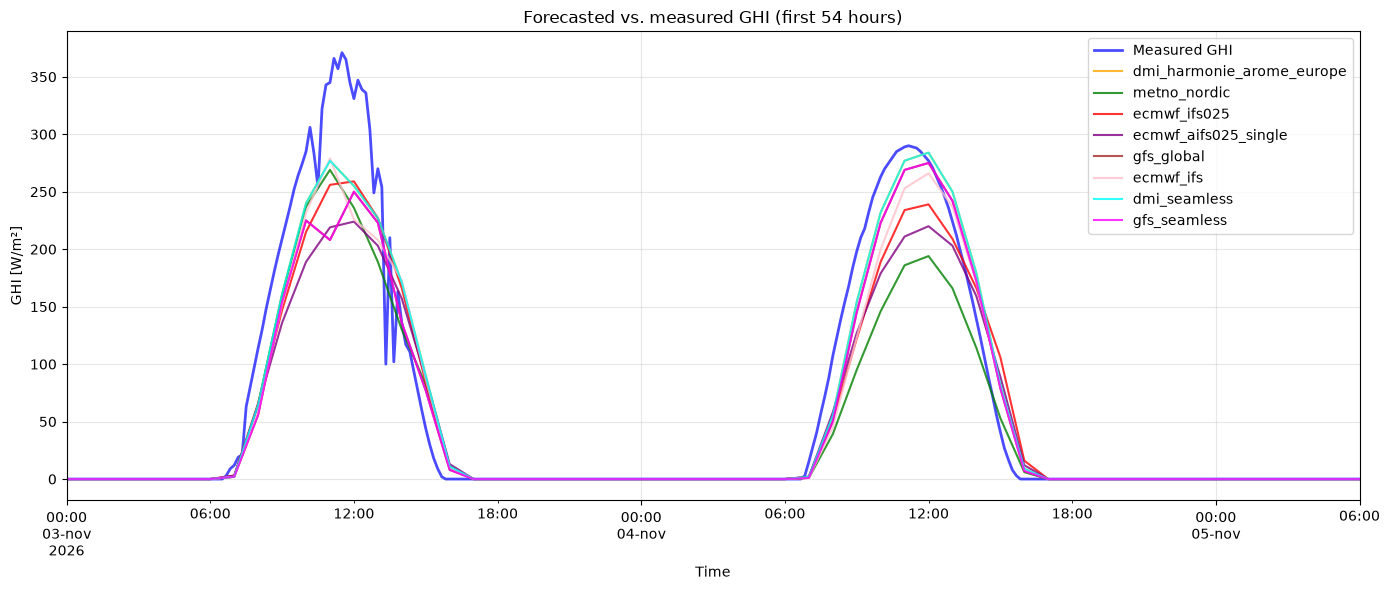

In [21]:
# Plotting the forecast data against the measured data

col_names = ['dmi_harmonie_arome_europe', 'metno_nordic', 'ecmwf_ifs025',
             'ecmwf_aifs025_single', 'gfs_global', 'ecmwf_ifs', 'dmi_seamless', 'gfs_seamless']
            
colors = ['orange', 'green', 'red', 'purple', 'brown', 'pink', 'cyan', 'magenta']

# Restrict to the first 54 hours of the forecast
start = forecast_data.index[0]
end = start + pd.Timedelta(hours=54)
fc = forecast_data.loc[start:end]
measured = dmi_data['ghi'].loc[start:end]

fig, ax = plt.subplots(figsize=(14, 6))

measured.plot(ax=ax, label='Measured GHI', color='blue', alpha=0.7, linewidth=2)

for name, color in zip(col_names, colors):
    fc[name].plot(ax=ax, label=name, color=color, alpha=0.8)

ax.set_xlabel('Time')
ax.set_ylabel('GHI [W/m²]')
ax.set_title('Forecasted vs. measured GHI (first 54 hours)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"results/prediction_performance/forecast_vs_measured_ghi_{start_date}_{end_date}.png", dpi=300)